# xNEW124 - Machine Learning : Linear Models

Andrés F. LOPEZ-LOPERA <br/>
Université de Montpellier

---

<div class="alert alert-block alert-warning"> 
    For this lab session, you are free to use the language of your choice but Python is strongly recommended. In this notebook we will focus on Python implementations based on the toolboxes 'numpy', 'matplotlib', 'pandas' and 'sklearn'.
    
</div>

In [1]:
import numpy as np              # toolbox with comprehensive mathematical functions
import matplotlib.pyplot as plt # toolbox for plotting figures
from matplotlib.colors import ListedColormap # to fix some colormaps
import pandas as pd             # toolbox for managing dataframes
import seaborn as sns           # toolbox for visualization

## Introduction

This notebook focuses on exercises related to classification and clustering models. More precisely, we will explore the following methods:

- Linear models for classification
    - Linear discriminant analysis (LDA)
- Clustering
    - $k$-means
    - Gaussian mixture models (GMMs)

## Exercice 1: Linear models for classification

### Iris dataset

In this exercise, we will use the **Iris dataset**, a well-known dataset in the machine learning community. It is readily available in the `sklearn` library. You can find more details in the official documentation here: [Iris dataset Documentation](https://scikit-learn.org/1.5/datasets/toy_dataset.html)

**Question 1 (data Analysis).** Load the **Iris dataset** and create a Pandas DataFrame with appropriately named columns for $(X, y)$. Use Python visualization tools to analyze the dataset.  

Write a brief report (maximum 10 lines) summarizing your findings, making explicit references to the figures included in your analysis.

In [2]:
from sklearn import datasets     # toolbox ML + datasets

# Loading the iris dataset
dataset_full = datasets.load_iris()
dataset_full

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [3]:
# creating a dataframe
dataset = pd.DataFrame(np.hstack((dataset_full.data, dataset_full.target[:, np.newaxis])))
dataset = dataset.set_axis(dataset_full.feature_names + ['y'], axis = 1)

dataset

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),y
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


In [4]:
# defining the design matrix
pattern_names = dataset_full.feature_names # names of the features
target_names = dataset_full.target_names   # names of the classes
n, d = dataset.shape # (nb of observations, input dimension + output)
K = len(target_names) # nb of classes

print("Classes:", target_names)
print("Patterns:", pattern_names)

Classes: ['setosa' 'versicolor' 'virginica']
Patterns: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


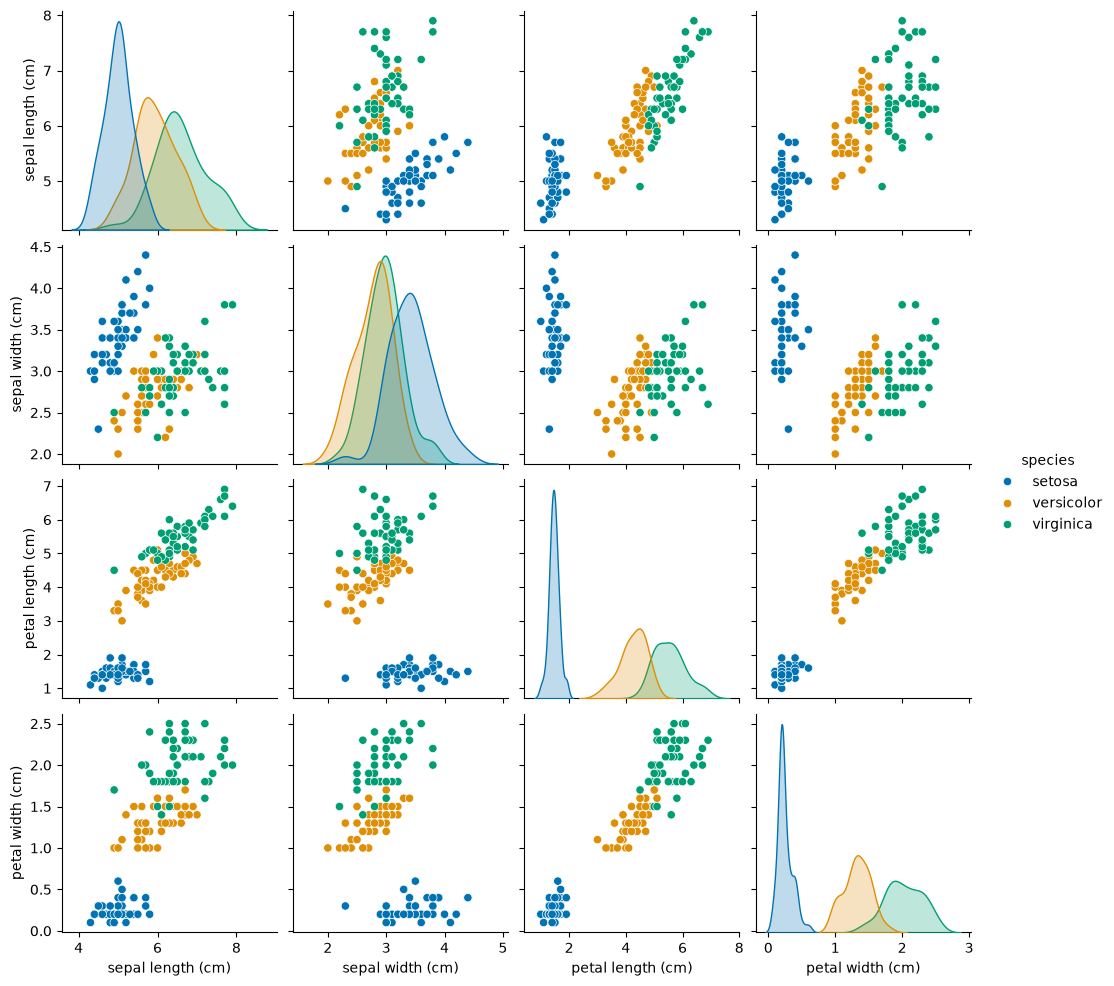

species                 setosa  versicolor  virginica
sepal length (cm) mean    5.01        5.94       6.59
                  std     0.35        0.52       0.64
sepal width (cm)  mean    3.43        2.77       2.97
                  std     0.38        0.31       0.32
petal length (cm) mean    1.46        4.26       5.55
                  std     0.17        0.47       0.55
petal width (cm)  mean    0.25        1.33       2.03
                  std     0.11        0.20       0.27

In [5]:
## to add your plots here
# class names as a categorical column (a copy: `dataset` keeps its numeric "y" for later use)
species = pd.Categorical.from_codes(dataset["y"].astype(int), target_names)
dataset_plot = dataset.drop(columns="y").assign(species=species)

# Figure 1: scatter plots of all pairs of features + per-class distributions on the diagonal
sns.pairplot(dataset_plot, hue="species", palette="colorblind")
plt.show()

# Table 1: mean and standard deviation of each feature per class
dataset_plot.groupby("species", observed=True).agg(["mean", "std"]).round(2).T


### Linear discriminant analysis in $\mathbb{R}^d$ for a binary classification

The probability density function of the observation $X$ given the class label $y \in \{0, 1\}$ follows a Gaussian distribution with a common covariance matrix $\Sigma \in \mathbb{R}^{d \times d}$:

\begin{align}
	f_{X| y = k}(x) 
    = \frac{1}{\sqrt{(2\pi)^d |\Sigma|}} \exp\left(- \frac{1}{2}(x-\mu_k)^\top \Sigma^{-1} (x-\mu_k)\right),
\end{align}

where $\mu_k \in \mathbb{R}^d$ represents the mean vector of the Gaussian distribution for class $k$. We assume prior probabilities $\mathbb{P}(y = k) = \pi_k$ for all $k \in \{0, 1\}$.  

The classification rule is given by

\begin{equation*}
    \eta_{\theta}(x) = \mathbb{1}_{\mathbb{P}(y = 1|x) \geq \mathbb{P}(y = 0|x)}
	\quad
	\Leftrightarrow
	\quad
	\eta_{\theta}(x) = \mathbb{1}_{\delta_1(x) \geq \delta_0(x)},
\end{equation*}
where $\delta_k$ is the linear discriminant function defined as  

\begin{align*}
    \delta_k(x) 
	&= \langle x, \Sigma^{-1} \mu_k \rangle - \frac{1}{2} \mu_k^\top \Sigma^{-1} \mu_k + \log \left(\pi_k \right).
\end{align*}

#### Parameter estimators

The parameters of the LDA model can be estimated using the maximum likelihood method. The first-order optimality conditions yield the following estimators:  

1. **Class Prior Probabilities:** The empirical estimates of the prior probabilities are given by  

   $$
   \hat{\pi}_k = \frac{n_k}{n}, \quad k \in \{0,1\},
   $$
   
   where $n_k$ is the number of observations in class $k$, and $n$ is the total number of observations.

2. **Class Means:** The maximum likelihood estimates of the class means are  
   
   $$
   \hat{\mu}_k = \sum_{i: y_i = k} \frac{x_i}{n_k}, \quad k \in \{0,1\}.
   $$

3. **Covariance Matrix:** Since LDA assumes a common covariance matrix across both classes, the pooled sample covariance estimate is  
   
   $$
    \hat{\Sigma}_k = \sum_{i : y_i = k} \frac{(x_i-\hat\mu_k)(x_i-\hat\mu_k)^\top}{n_k-1}, \quad
	\hat{\Sigma} = \sum_{k = 0}^{1}  \frac{n_k-1}{n-2} \hat{\Sigma}_k, \quad k \in \{0,1\}.
   $$

These estimates can then be used to construct the linear discriminant functions and derive the corresponding decision rule.  

**Question 2 (Implemention of LDA in $\mathbb{R}^2$ from Scratch).** Consider a binary classification problem involving only the `setosa` and `versicolor` classes (i.e., exclude data related to `virginica`). Focus on the features `petal length (cm)` and `petal width (cm)`.  

Using the formulas derived in the course, compute the estimators of the following parameters:  
- Class priors: $\hat{\pi}_k$  
- Class means: $\hat{\mu}_k$  
- Class covariance matrices: $\hat{\Sigma}_k$  
- Shared covariance matrix: $\hat{\Sigma}$  

In a single panel, create a scatterplot of the data points and display the estimated means $\hat{\mu}_k$. Additionally, visualize the estimated local covariances $\hat{\Sigma}_k$ by plotting ellipsoids using four contour levels. The `Ellipse` function from `matplotlib.patches` can be useful for this purpose.  

Finally, apply the LDA classification rule to compute predictions and report the model's accuracy.

In [6]:
def plot_points(X, y, target_names):
    for k in range(len(target_names)):
        ax.scatter(X[y == k, 0], X[y == k, 1], label = target_names[k], s = 20)
    ax.set(xlabel = dataset_full.feature_names[2],
           ylabel = dataset_full.feature_names[3])
    plt.legend(loc=4);

In [7]:
from sklearn.metrics import accuracy_score
from matplotlib.patches import Ellipse

# Function to plot Gaussian ellipses
def plot_LDA_ellipses(means, covariances, ax):
    colors = sns.color_palette("colorblind", 2)
    for i, (mean, covar) in enumerate(zip(means, covariances)):
        eigenvalues, eigenvectors = np.linalg.eigh(covar)
        order = eigenvalues.argsort()[::-1]
        eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
        angle = np.degrees(np.arctan2(*eigenvectors[:, 0][::-1]))
        volume = np.linalg.det(covar)**(1/len(mean))        
        width, height = 2*np.sqrt(eigenvalues/volume)
        for ncontour in range(4):
            ellipse = Ellipse(mean, (ncontour+1)*width/2, (ncontour+1)*height/2, angle = angle, 
                              edgecolor = colors[i], facecolor = colors[i], lw = 2, alpha = 0.2)
            ax.add_patch(ellipse);

In [8]:
pattern_names_2d = pattern_names[2:4] # defining target features
target_names_bin = target_names[:2]     # defining target classes

X = np.array(dataset[pattern_names_2d])  # extracting X related to the petal 
y = np.array(dataset["y"])                # extracting y  

idx_keep = y != 2  # discarding data with class "setosa" 
y = y[idx_keep]    # to ensure y \in {0, 1} 
X = X[idx_keep, :]
nbin = X.shape[0]  # (nb of observations, input dimension + output)

In [9]:
pi_hat = [None] * 2                # pi parameters
mu_hat = [None] * 2                # mean parameters
Sigma_hat_local = [None] * 2       # local covariance parameters
Sigma_hat_shared = np.zeros((2,2)) # shared covariance parameter

for k in range(2):
    idx_k = (y == k)
    nk = np.sum(idx_k)
    Xk, yk = X[idx_k, :], y[idx_k]
    
    pi_hat[k] = nk / nbin
    mu_hat[k] = Xk.mean(axis = 0)
    Sigma_hat_local[k] = (Xk - mu_hat[k]).T @ (Xk - mu_hat[k]) / (nk - 1)
    Sigma_hat_shared += (nk - 1) / (nbin - 2) * Sigma_hat_local[k]

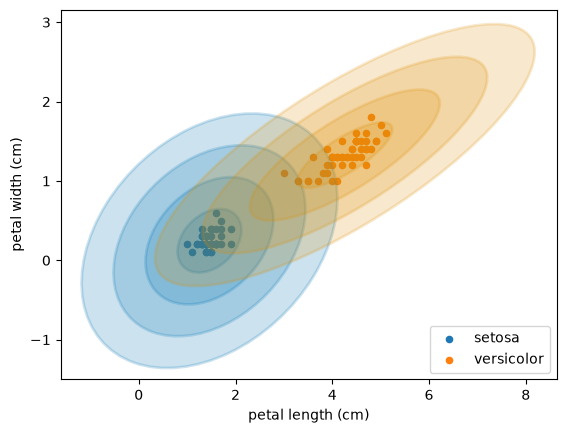

In [10]:
fig, ax = plt.subplots()
plot_points(X, y, target_names_bin)
plot_LDA_ellipses(mu_hat, Sigma_hat_local, ax)

In [11]:
# Computing the coefficients of the separation hyper-plane
Sigma_inv = np.linalg.inv(Sigma_hat_shared) 
beta = Sigma_inv @ (mu_hat[1] - mu_hat[0])
beta0 = 0.5 * (mu_hat[0].T @ Sigma_inv @ mu_hat[0] - mu_hat[1].T @ Sigma_inv @ mu_hat[1]) + np.log(pi_hat[1]/pi_hat[0])

y_pred = [int(X[i, :] @ beta >= - beta0) for i in range(nbin)]
print("accuracy:", np.sum(y_pred == y) / nbin)
print("accuracy (sklearn):", accuracy_score(y_pred, y))

accuracy: 1.0
accuracy (sklearn): 1.0


(too add your comments here)

**Question 3 (LDA using sklearn).** Repeat **Question 2**, this time using the `LinearDiscriminantAnalysis` class from `sklearn` ([LDA Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html)). Compare the decision boundaries obtained with those from the previous method. Analyze any differences you observe. 

Adapt the code for a classification problem involving three classes: `setosa`, `versicolor`, and `virginica` from the Iris dataset. Report your findings.  

In [12]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

clf_LDA = LinearDiscriminantAnalysis()
y_LDA = clf_LDA.fit(X, y).predict(X)
accuracy_score(y, y_LDA)

1.0

In [13]:
# Three-class model
X = np.array(dataset[pattern_names_2d])  # extracting X related to the petal 
y = np.array(dataset["y"])                # extracting y  

clf_LDA = LinearDiscriminantAnalysis()
y_LDA = clf_LDA.fit(X, y).predict(X)
accuracy_score(y, y_LDA)

0.96

**Question 4 (plotting the decision boundary).** The function `frontier` visualizes the decision boundary of a classifier by evaluating it on a grid of points, considering the range of input variables in the dataset $X$. It requires the following arguments:  
- `X` : feature matrix $X \in \mathbb{R}^{n \times d}$  
- `y` : fround truth labels $y \in \mathbb{N}$  
- `resolution` : number of points per dimension to construct the grid  
- `f` : classification function $f: \mathbb{R}^{d} \to \mathbb{N}$, which assigns a class label to a given input  

Modify your sklearn-based code to ensure compatibility with `frontier`, then use it to visualize the decision boundary. Finally, display the results and analyze your observations.  

In [14]:
def frontier(f, X, y, step = 100):
    """ function for plotting the decision frontier of a binary classifier f """    
    # converting data to np.arrays
    X, y = np.array(X), np.array(y)
    
    # defining a grid of test points for evaluation
    eps = 0.1
    min_x0, max_x0 = np.min(X[:, 0])-eps, np.max(X[:, 0])+eps
    min_x1, max_x1 = np.min(X[:, 1])-eps, np.max(X[:, 1])+eps
    x1, x2 = np.meshgrid(np.arange(min_x0, max_x0, (max_x0 - min_x0) / step),
                         np.arange(min_x1, max_x1, (max_x1 - min_x1) / step))
    
    # computing the predictions for each point in the test grid
    z = np.array([f(vec) for vec in np.c_[x1.ravel(), x2.ravel()]]).reshape(x1.shape)
    pred_labels = np.unique(z)
    
    #  defining colormap to have similar colors to the points
    color_blind_list = sns.color_palette("colorblind", pred_labels.shape[0])
    sns.set_palette(color_blind_list)
    cmap = ListedColormap(color_blind_list)
    
    # plotting prediction map 
    plt.imshow(z, origin = 'lower', extent = [min_x0, max_x0, min_x1, max_x1],
               interpolation = 'mitchell', alpha = 0.80, cmap = cmap, aspect='auto')
    ax = plt.gca()
    cbar = plt.colorbar(ticks = pred_labels)
    cbar.ax.set_yticklabels(pred_labels)

    labels = np.unique(y).shape[0]
    color_blind_list = sns.color_palette("colorblind", labels)
    for i, label in enumerate(y):
        plt.scatter(X[i, 0], X[i, 1],
                    color = color_blind_list[int(y[i])], s = 80)
    plt.xlim([min_x0, max_x0])
    plt.ylim([min_x1, max_x1]);

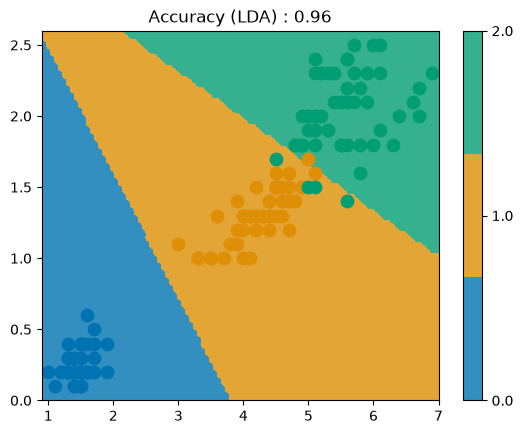

In [15]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

def f(x):
    """Classifier"""
    return(clf_LDA.predict(x.reshape(1, -1))[0])

nb_steps = 100
fig = plt.figure()
title = "Accuracy (LDA) " + \
        ": {:.2f}".format(accuracy_score(y, clf_LDA.predict(X)))
frontier(f, X, y, nb_steps)
plt.title(title)
plt.show()

## Exercice 2: Clustering

**Question 1 ($k$ means from scratch).** Consider the **Iris dataset**. As in **Exercise 1**, focus on the features related to `petal length (cm)` and `petal width (cm)`. Implement Lloyd's algorithm for $k$-means clustering as discussed in the course for $K$ classes. In your experiments, consider $K = 3$. Initialize randomly the centroids of the algorithm. During the process, plot the results of each iteration to visualize the clustering progress. Define a stopping criterion for the algorithm.

Repeat the previous procedure for different random initializations and different values of $K$. What can you conclude?

In [16]:
def dist_euclidean(x, y):
    return()

def my_kmeans_plot(X, centroids, n_iter_max):
    colors = sns.color_palette("colorblind", len(centroids))

    n_obs = X.shape[0]
    n_clusters = len(centroids)
    pred = np.zeros(X.shape[0])
    
    for n in range(n_iter_max):
        # Step 1: assigning points to classes according to the neareast centroid
        for i in range(n_obs):
            dists_temp = 
            pred[i] = 
            
        # Step 2: updating the centroids
        centroids =
        
        _, ax = plt.subplots()
        for k in range(len(target_names)):
            ax.scatter(X[pred == k, 0], X[pred == k, 1], label = target_names[k], s = 20)
            ax.scatter(centroids[k, 0], centroids[k, 1], marker = 'x', 
                       s = 80, linewidths = 3, color = colors[k], zorder = 10)
        ax.set(xlabel = dataset_full.feature_names[2],
               ylabel = dataset_full.feature_names[3])
        
    return((pred, centroids))

SyntaxError: invalid syntax (566257584.py, line 14)

In [ ]:
X = np.array(dataset[pattern_names_2d])  # extracting X related to the petal 
n_clusters = # defining nb of clusters

# random initialization of the centroids
np.random.seed(13)
centroids = np.vstack((np.random.uniform(min(X[:,0]), max(X[:,0]), n_clusters),
                       np.random.uniform(min(X[:,1]), max(X[:,1]), n_clusters))).T

y_kmeans, centroids_pred = my_kmeans_plot(X, centroids, 5)

**Question 2 (plotting the decision boundary).** Using the function `frontier`, visualize the decision boundary of the $k$-means clustering algorithm. Given the true labels available in the dataset, compute the accuracy of the model. You may need to adjust the predicted labels to account for any identification issues.

In [ ]:
def f(x):
    """ k-means """
    dists = 
    return(np.argmin(np.array(dists))) 

fig = plt.figure()
title = "Accuracy (k-means) " + \
        ": {:.2f}".format(accuracy_score(y, y_kmeans))
frontier(f, X, y, nb_steps)
plt.title(title)
plt.show()

**Question 3 (GMM using sklearn).** Repeat **Questions 1-2** using a Gaussian Mixture Model (GMM) with three mixture components. You can use the `GaussianMixture` function available in `sklearn` ([GMM Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html)).

For displaying the results, first plot the corresponding centers and ellipsoids of each Gaussian component. You may use the `plot_gmm_ellipses` function to pass the means and covariances of the GMM. 

Next, visualize the decision boundary using the `frontier` function from **Exercise 1 (Question 4)**. What can you conclude?

In [ ]:
from matplotlib.patches import Ellipse
colors = sns.color_palette("colorblind", n_clusters)

# Function to plot Gaussian ellipses
def plot_gmm_ellipses(gmm, ax, colors):
    for i, (mean, covar) in enumerate(zip(gmm.means_, gmm.covariances_)):
        if covar.ndim == 1:  # Ensure covariance is 2D
            covar = np.diag(covar)
        eigenvalues, eigenvectors = np.linalg.eigh(covar)
        order = eigenvalues.argsort()[::-1]
        eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
        angle = np.degrees(np.arctan2(*eigenvectors[:, 0][::-1]))
        volume =  np.linalg.det(covar)**(1/len(mean))        
        width, height = np.sqrt(eigenvalues / volume)
        for ncontour in range(2):
            ellipse = Ellipse(mean, (ncontour+1)*width, (ncontour+1)*height, angle = angle,
                              edgecolor=colors[i], facecolor=colors[i], lw=2, alpha = 0.2)
            ax.add_patch(ellipse);

In [ ]:
from sklearn.mixture import GaussianMixture

# fitting a Gaussian Mixture Model
gmm = # GaussianMixture(...)
# gmm.fit(...)
y_gmm = # gmm.predict(...)

# plotting points and ellipses
fig, ax = plt.subplots()
for i in range(n_clusters):
    points = X[y_gmm == i]
    ax.scatter(points[:, 0], points[:, 1], s=30, color=colors[i], label="$\\mathcal{C}_" + str(i+1) + "$")
    
plot_gmm_ellipses(gmm, ax, colors)
ax.set(xlabel = dataset_full.feature_names[2],
       ylabel = dataset_full.feature_names[3])
ax.legend(loc=4);

In [ ]:
print("weights:", gmm.weights_)
print("means:", gmm.means_)
print("covariances:", gmm.covariances_)

In [ ]:
def f(x):
    """ gmm """
    return() 

# plotting the decision boundary
fig = plt.figure()
title = "Accuracy (GMM) " + \
        ": {:.2f}".format(accuracy_score(y, y_gmm))
frontier(f, X, y, nb_steps)
plt.title(title)
plt.show()